# Integrating data using ingest and BBKNN

### Aim:
Two method of combining single-cell datasets from different experiments (ingest and BBKNN), reducing batch effect
- ingest (reference mapping): take an annotated dataset and project new dataset onto it, transferring the reference's cell-type labels and UMAP positions. 
- BBKNN (joint integration): rebuild the neighbour graph so that each cell's neighbours are drawn evenly from every batch, reducing the batch effect without changing the expression values.

### Data:
| part | reference | query/batches |
|---|---|---|
|1. PBMCs| pbmc3k_processed: about 2,6000 blood cells, already clustered and labelled with cell types| pbmc68k_reduced: a small subset(700 cells) of a larger PBMC dataset from a different experiment with own independent labels (bulk_labels) to check the mapping against|
|2. Pancreas| one study used as the reference| three other pancreas studies, about 14,700 cells in total with strong batch effect between studies| 

### Workflow:
1. Keep only genes intersected by both datasets
2. Build PCA, neighbours and UMAP on the reference
3. ingest: project the query onto the reference and transfer labels
4. BBKNN: combine the dataset and build a batch-baanced neighbour graph
5. Compare the two approaches, then repeat on the harder pancreas data
6. Check how well labels trnasferred (confsion tables of transferred vs original lables) and visualise batches

### Expected output:
UMAPs where cells from different datasets overlap by cell type, trnasferred labels on the query cells and tables showing how well they agreee with original annotations


Ingest and BBKNN comparison table

| | ingest | BBKNN|
|---|---|---|
| type | asymmetric | symmetric|
| idea | one datasetis fixed map, others are placed onto it | all datasets are treated equally and combined into a new shared space|
| reference | one dataset, does not changed | references changes and everything is recalculated together|
| main output | labels and positions for the new dataset | a joint graph or embedding of everything |


In [1]:
# import libraries
from __future__ import annotations

import anndata
import pandas as pd
import scanpy as sc

sc.logging.print_header()

/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/IPython/core/formatters.py:1035: RuntimeWarning: Failed to import dependencies for application/vnd.jupyter.widget-view+json representation. (ModuleNotFoundError: No module named 'ipywidgets')
  return method(include=include, exclude=exclude)


Package,Version
anndata,0.13.4
pandas,3.0.6
scanpy,1.12.4
Component,Info
Python,"3.12.8 | packaged by Anaconda, Inc. | (main, Dec 11 2024, 10:37:40) [Clang 14.0.6 ]"
OS,macOS-15.3.1-arm64-arm-64bit
CPU,"8/8 logical CPU cores, arm"
GPU,No GPU found
Updated,2026-10-06 17:15
Dependency,Version


In [2]:
# settings
sc.settings.verbosity = 1 # letting scanpy print errors and warnings but not progress information
sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(3, 3), facecolor="white")


/var/folders/df/6k2bwzwx1t921dqfsfctvxrc0000gn/T/ipykernel_93013/1675216286.py:3: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(3, 3), facecolor="white")


In [3]:
# load data
adata_ref = sc.datasets.pbmc3k_processed() 
# reference dataset, clustered with Louvain method
adata = sc.datasets.pbmc68k_reduced() 
# query dataset, different donor and experiment from pbmc 3k dataset
# clustered with bulk_labels

In [4]:
# keep only intersecting genes
var_names = adata_ref.var_names.intersection(adata.var_names)
adata_ref = adata_ref[:, var_names].copy()
adata = adata[:, var_names].copy()

# making sure both datasets have exactly the same gens in the same order

In [5]:
# bulding the map on the reference dataset
sc.pp.pca(adata_ref)
sc.pp.neighbors(adata_ref)
sc.tl.umap(adata_ref)

/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


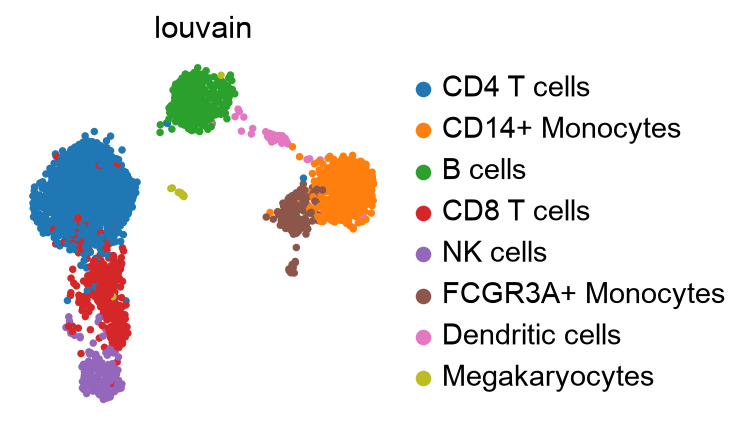

In [6]:
# checking the reference map
sc.pl.umap(adata_ref, color="louvain") 

# louvain clustering - clusters named as cell types like CD4 T cells...
# closer clusters in UMAP means similar gene expression profiles 
    # so T cells like CD4 T cells and CD8 T cells are closer to each other than to B cells

## Mapping PBMCs using ingest

Mapping labels and embeddings from reference dataset (adata_ref) to query dataset (adata)

In [7]:
sc.tl.ingest(adata, adata_ref, obs= "louvain")

# this replaces the query's numbered louvain column with the reference's louvain column, 
# so now the query's louvain column is named as cell types like CD4 T cells...
# eg. cell_1 -> "3" ===> cell_1 -> "CD4 T cells"
    # its because two datasets are in different stages of the process that reference's louvain column has cell-type names
    # while query's louvain column has numbers

In [8]:
# matching colours
adata.uns["louvain_colors"] = adata_ref.uns["louvain_colors"]

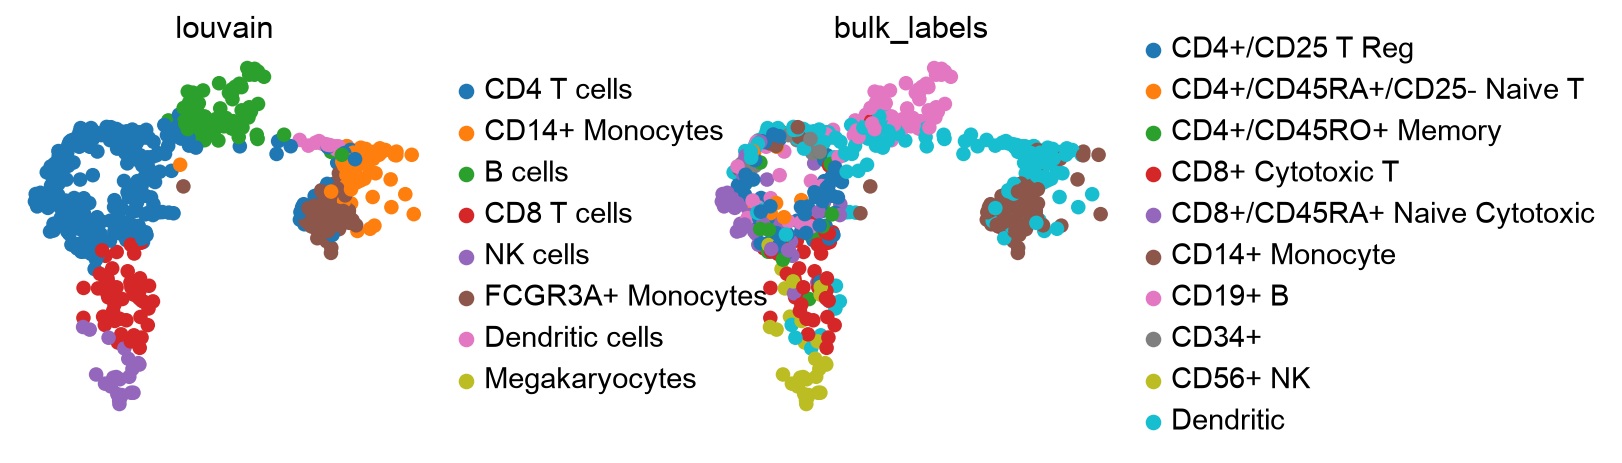

In [9]:
# checking the transferred labels
sc.pl.umap(adata, color=["louvain", "bulk_labels"], wspace=0.5)

# louvain shows the labels that ingest just predicted 
# bulk_labels shows the labels that were already in the query dataset
# overall seems ingest predicted well but not dendritic cells

In [10]:
# putting both datasets in one object
adata_concat = anndata.concat([adata_ref, adata], label="batch", keys={"ref", "new"})

In [11]:
# fixing the category order
adata_concat.obs["louvain"] = (
    adata_concat.obs["louvain"].astype("category").cat.reorder_categories(adata_ref.obs["louvain"].cat.categories))

In [12]:
# copying the colours again
adata_concat.uns["louvain_colors"] = adata_ref.uns["louvain_colors"]

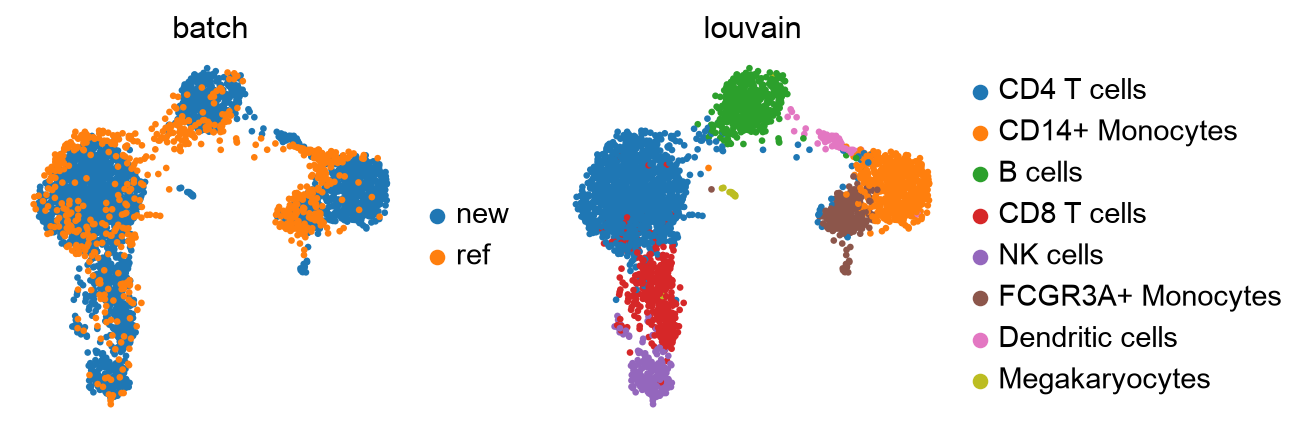

In [13]:
# the integration check
sc.pl.umap(adata_concat, color=["batch", "louvain"])

# batch effect in monocytes and dendritic cells
# megakaryocytes with only reference cells

The reference limist what ingest can find. If the query contain cell type that was not in the reference, ingest forces those cells into the nearest existing type and mislabel them. In cancer research when we compare healty vs malignant cells, this can mislabel malignant cells inot nearest existing normal cell type or tumour specific immune states like exhausted T cell can be labelled as generic CD8 T cells, leading to false negative. 

## Using BBKNN (batch-balnced K-nearest neighbours method)

build new map from both datasets together, treating them equally
each cell must take neighbours from every batch in equal numbers (default 3 from each batch). 

In [18]:
adata_bbknn = adata_concat.copy()

In [19]:
import bbknn

# new PCA on both dataset together
sc.tl.pca(adata_bbknn)

# this calculate new PCA using all cells from both datasets together 

In [20]:
# the batch-balanced neighbour graph
bbknn.bbknn(adata_bbknn, batch_key="batch", computation="cKDTree")

In [21]:
# new UMAP from the new graph
sc.tl.umap(adata_bbknn)

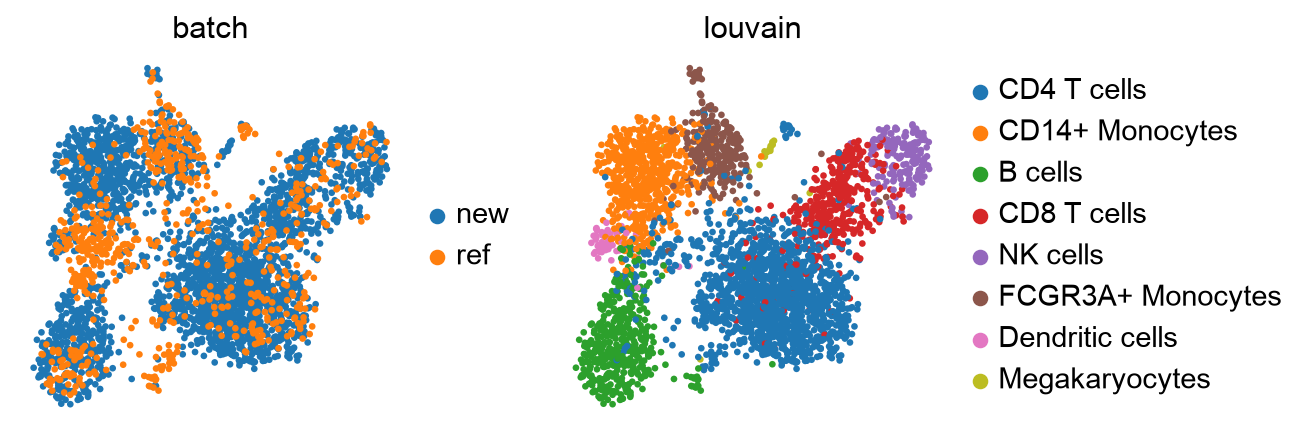

In [ ]:
# checking the resutls
sc.pl.umap(adata_bbknn, color=["batch", "louvain"])

BBKNN formed well the new map as the batch panel shows the two datasets mixed within each cell-type group. 

# Part 2 Pancreas - from 4 different studies

Study 0 - Baron et al., 2016, 
Study 1 - Muraro et al., 2016, 
Study 2 - Segerstolpe et al., 
Study 3 - 2016, Wang et al., 2016

Integating four pancreas studies with strong batch effect. We will compare ingest and BBKNN and measure how well each method combining these datasets. 

### workflow
1. Load the data, remove the 5 rarest cell types
2. PCA -> neighbours -> UMAP on everyting to see the batch effect
3. BBKNN to fix it
4. ingest - use study 0 as reference, map studies 1-3 onto it
5. evaluate confusion tables of ingest lables vs original labels 
6. Visualise where each batch's cells sit using density plots

Pancreas biology for better understanding of cell types

| group | cell types | role |
|---|---|---|
| endocrine (islets) | alpha (glucagon), beta (insulin), delta (somatostatin), gamma (pancreatic polypeptide), epsilon (ghrelin) | hormone production, blood sugar control |
| exocrine | acinar (digestive enzymes), ductal (lines the ducts that carry enzymes) | digestion |
| support | stellate (fibroblast-like; "activated" during injury or fibrosis), endothelial (blood vessels), schwann (nerves) | structure |
| immune | macrophage, mast, t_cell | defence | 

In [23]:
# note that this collection of batches is already intersected on the genes
adata_all = sc.read(
    "data/pancreas.h5ad",
    backup_url="https://www.dropbox.com/s/qj1jlm9w10wmt0u/pancreas.h5ad?dl=1",
)

adata_all.shape

100%|██████████| 176M/176M [00:08<00:00, 21.9MB/s] 
/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:836: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  return read_h5ad(filename, backed=backed)
/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:836: FutureWarning: Moving element from .uns['neighbors']['connectivities'] to .obsp['connectivities'].

This is where adjacency matrices should go now.
  return read_h5ad(filename, backed=backed)


(14693, 2448)

In [ ]:
# looking at cell types
counts = adata_all.obs["celltype"].value_counts()
counts.to_frame()

# not applicable, droppped, co-expression, unclassified endocrine, unclear
# these are kept in the dataset to let ingest know that 
# these cells are not to be used for training the model, 
# but they are still in the dataset to be predicted on

,count
celltype,
alpha,4214
beta,3354
ductal,1804
acinar,1368
not applicable,1154
delta,917
gamma,571
endothelial,289
activated_stellate,284


In [25]:
# removing 5 rarest classes and reordering the remaining 19 categories (from most to least common)
minority_classes = counts.index[-5:].tolist()
adata_all = adata_all[~adata_all.obs["celltype"].isin(minority_classes)].copy()
adata_all.obs["celltype"] = adata_all.obs["celltype"].cat.reorder_categories(counts.index[:-5].tolist())

### Seeing the batch effect

In [26]:
sc.pp.pca(adata_all)
sc.pp.neighbors(adata_all)
sc.tl.umap(adata_all)

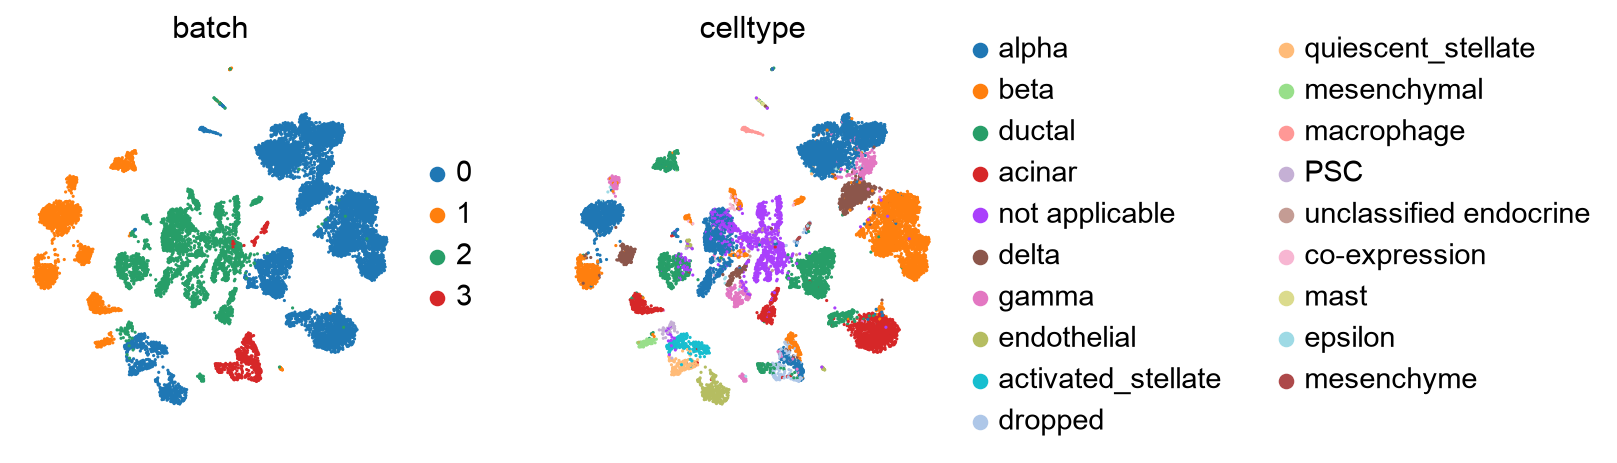

In [27]:
sc.pl.umap(adata_all, color=["batch", "celltype"], palette=sc.pl.palettes.vega_20_scanpy)
# since we have 19 categories, we use vega_20 palette which has 20 colours, so that each category has a different colour

Each batch and each cell type separated quite clearly which represents strong batch effect - technical differences between studies outweigh biological differences between some cell types. 

### BBKNN

In [35]:
import bbknn
bbknn.bbknn(adata_all, batch_key="batch", computation="cKDTree")

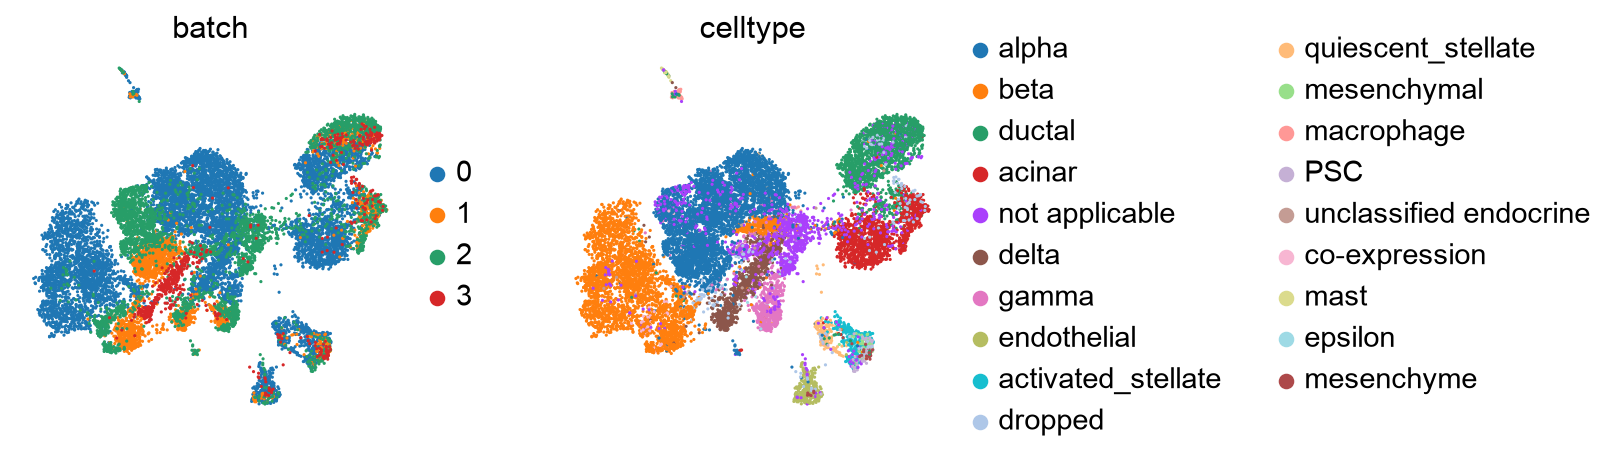

In [36]:
sc.tl.umap(adata_all)
sc.pl.umap(adata_all, color=["batch", "celltype"])

Batches mixed and each cell type forming one island with cells from all studies. 

### Mapping onto a reference batch using ingest

In [37]:
adata_ref = adata_all[adata_all.obs["batch"] == "0"].copy()

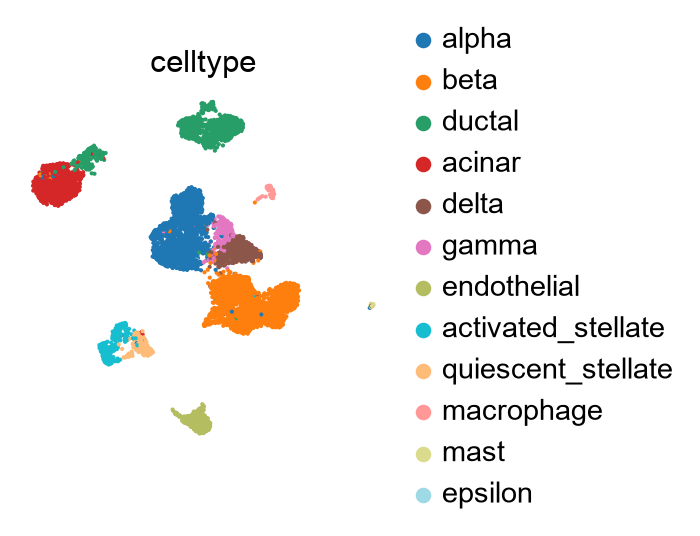

In [ ]:
# reference map from study 0 only 
sc.pp.pca(adata_ref)
sc.pp.neighbors(adata_ref)
sc.tl.umap(adata_ref)
sc.pl.umap(adata_ref, color="celltype")

# this reference study does not contain all 19 cell types 
# so some cell types only in other studies 
# so query cells of those types cannot get their correct label

In [ ]:
adatas = [adata_all[adata_all.obs["batch"] == i].copy() for i in ["1", "2", "3"]]

In [ ]:
sc.settings.verbosity = 2

for iadata, adata in enumerate(adatas, 1):
    print(f"... integrating batch {iadata}")
    adata.obs["celltype_orig"] = adata.obs["celltype"]
    # saves the original columns in separate column as ingest will overwrite celltype column with the predicted labels
    sc.tl.ingest(adata, adata_ref, obs="celltype")

... integrating batch 1
running ingest
    finished (0:00:02)
... integrating batch 2
running ingest
    finished (0:00:01)
... integrating batch 3
running ingest
    finished (0:00:01)


In [41]:
# combining results
adata_concat = anndata.concat([adata_ref, *adatas], label="batch", join="outer")

In [42]:
adata_concat.obs["celltype"] = (
    adata_concat.obs["celltype"].astype("category").cat.reorder_categories(adata_ref.obs["celltype"].cat.categories)
)
# fix category coloring
adata_concat.uns["celltype_colors"] = adata_ref.uns["celltype_colors"]

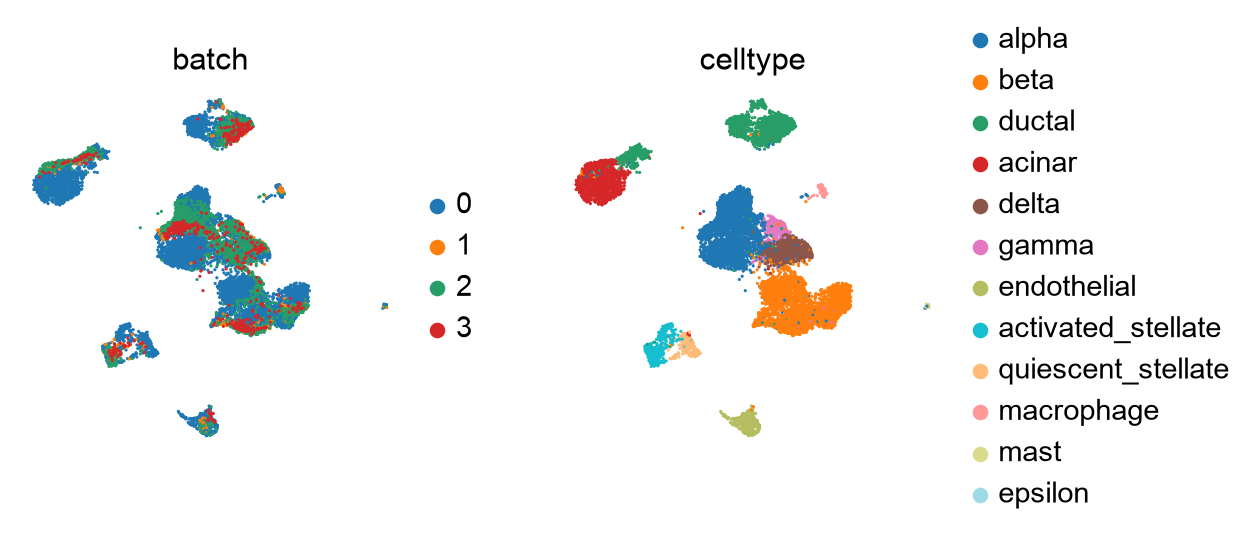

In [43]:
sc.pl.umap(adata_concat, color=["batch", "celltype"])

Cell types are well separated than with BBKNN. Ingest keep the reference's structure intact while BBKNN builds a compromise map. 

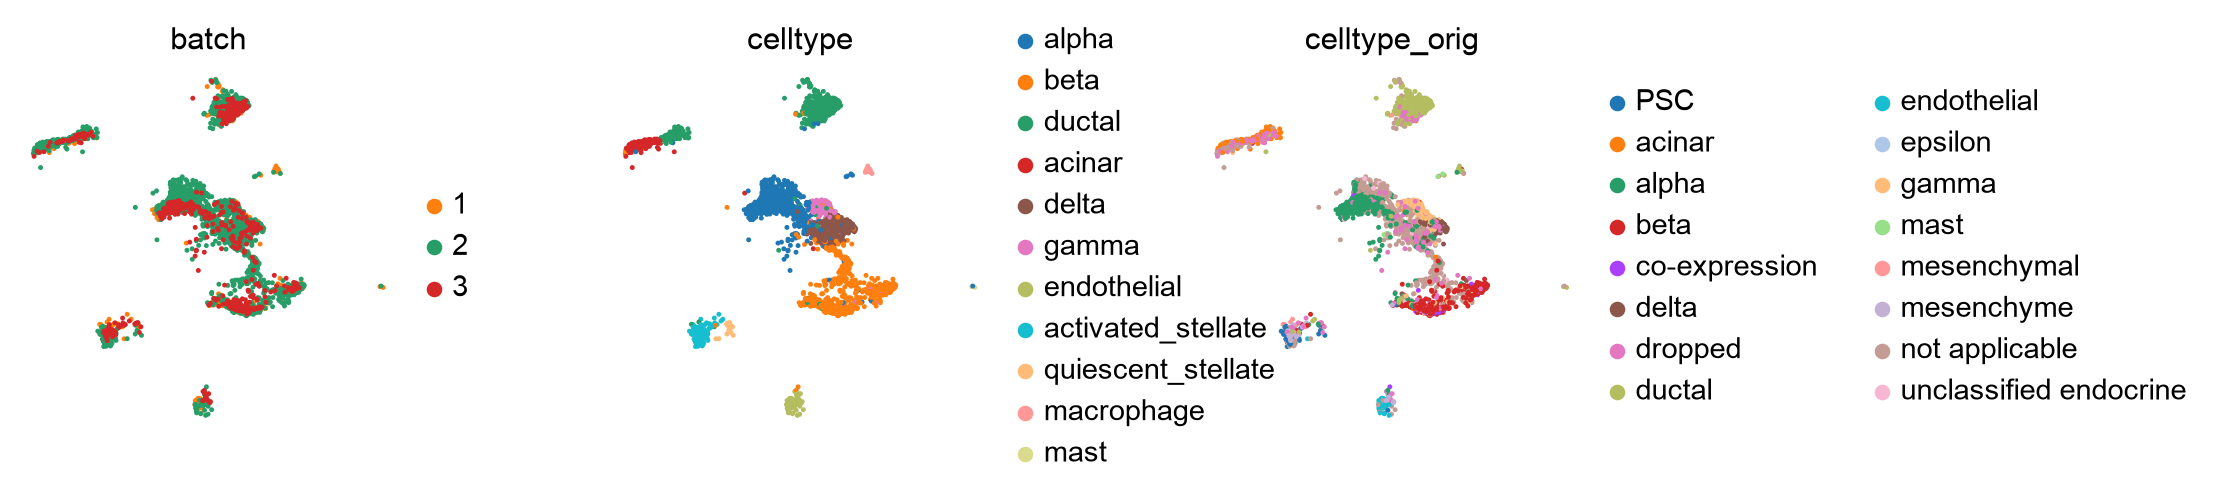

In [45]:
# evaluating consistency
adata_query = adata_concat[adata_concat.obs["batch"].isin(["1", "2", "3"])].copy()

# keeping only the query cells as only they have both predicted and original labels

sc.pl.umap(adata_query, color=["batch", "celltype", "celltype_orig"], wspace=0.4)

In [ ]:
# table of cell types conserved across batches
conserved_categories = adata_query.obs["celltype"].cat.categories.intersection(
    adata_query.obs["celltype_orig"].cat.categories
)
# finds label names that appear in both columns, so that we can check if the predicted labels match the original labels

obs_query_conserved = adata_query.obs.loc[
    adata_query.obs["celltype"].isin(conserved_categories) & adata_query.obs["celltype_orig"].isin(conserved_categories)
].copy()
# keeps cells where both predicted and original labels are shared names

obs_query_conserved["celltype"] = obs_query_conserved["celltype"].cat.remove_unused_categories()
obs_query_conserved["celltype_orig"] = (
    obs_query_conserved["celltype_orig"]
    .cat.remove_unused_categories()
    .cat.reorder_categories(obs_query_conserved["celltype"].cat.categories)
)

pd.crosstab(obs_query_conserved["celltype"], obs_query_conserved["celltype_orig"])
# rows are predicted labels, columns are original labels
# comparing to tutorial table this has mast column. it's because the reference study 0 has few mast cells
# tutorial ingest did not predict any mast cells but here ingest predicted 2 cells as mast cells
# this shows how unreliable predictions get for a tiny reference group

celltype_orig,alpha,beta,ductal,acinar,delta,gamma,endothelial,mast
celltype,,,,,,,,
alpha,1822,2,7,1,0,24,0,7
beta,35,807,10,1,16,36,0,0
ductal,7,7,689,293,0,0,0,0
acinar,0,1,1,113,0,2,0,0
delta,16,1,2,0,300,35,0,0
gamma,4,6,0,1,0,219,0,0
endothelial,1,0,0,0,0,0,36,0
mast,0,0,2,0,0,0,0,0


In [ ]:
# table for all cell types 
pd.crosstab(adata_query.obs["celltype"], adata_query.obs["celltype_orig"])

# this include labels that reference does not have
#  (+) not applicable from query mostly got mapped to beta and alpha
    # real cells without labels are mostly beta and alpha cells, so ingest predicted them as beta and alpha
    # meaning that for new dataset, less manual work for annotating cells without labels, as ingest can predict them as the most likely cell types
#  (+) two names for the same cell type, so they got mapped to the same label (well harmonised)
#  (-) epsilon cells do not exist in the reference so mis mapped as delta, alpha and other tyeps
#  (-) mast cells also mis mapped as alpha as reference do not have them

# overall if the reference dataset does not have a cell type, the query cells of that type will be misclassified as other types
# if reference dataset have a cell type, high agreement between predicted and original labels, so ingest works well for those cell types

celltype_orig,PSC,acinar,alpha,beta,co-expression,delta,dropped,ductal,endothelial,epsilon,gamma,mast,mesenchymal,mesenchyme,not applicable,unclassified endocrine
celltype,,,,,,,,,,,,,,,,
alpha,0,1,1822,2,4,0,25,7,0,5,24,7,0,0,439,17
beta,1,1,35,807,35,16,48,10,0,0,36,0,0,1,223,16
ductal,1,293,7,7,0,0,49,689,0,0,0,0,4,0,118,1
acinar,0,113,0,1,0,0,11,1,0,0,2,0,0,0,72,0
delta,0,0,16,1,0,300,20,2,0,2,35,0,0,0,259,7
gamma,0,1,4,6,0,0,2,0,0,3,219,0,0,0,18,0
endothelial,1,0,1,0,0,0,6,0,36,0,0,0,0,6,7,0
activated_stellate,47,1,1,3,0,0,11,4,0,0,0,0,76,20,16,0
quiescent_stellate,4,0,1,1,0,0,6,1,1,0,0,0,0,0,1,0


### visualising batches

computing density on 'umap'


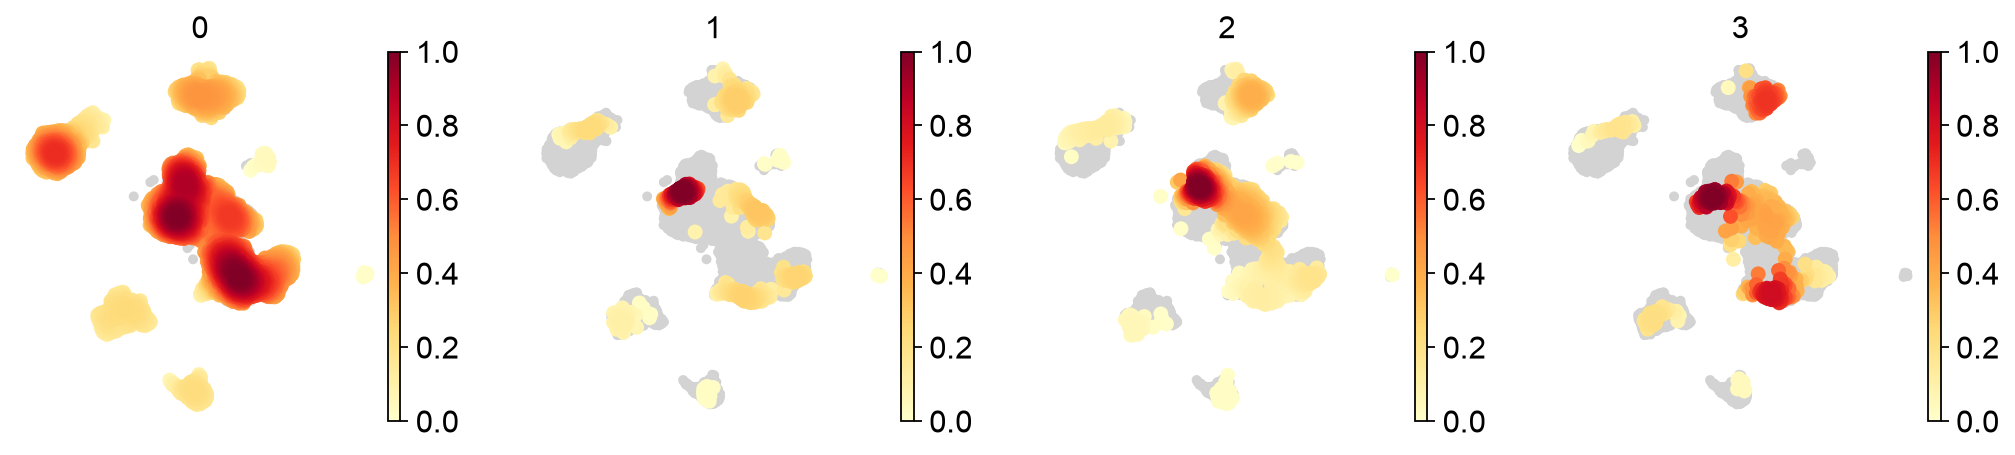

In [ ]:
# density plot
sc.tl.embedding_density(adata_concat, groupby="batch")
sc.pl.embedding_density(adata_concat, groupby="batch")

# represent where on the UMAP its cells are most concentrated

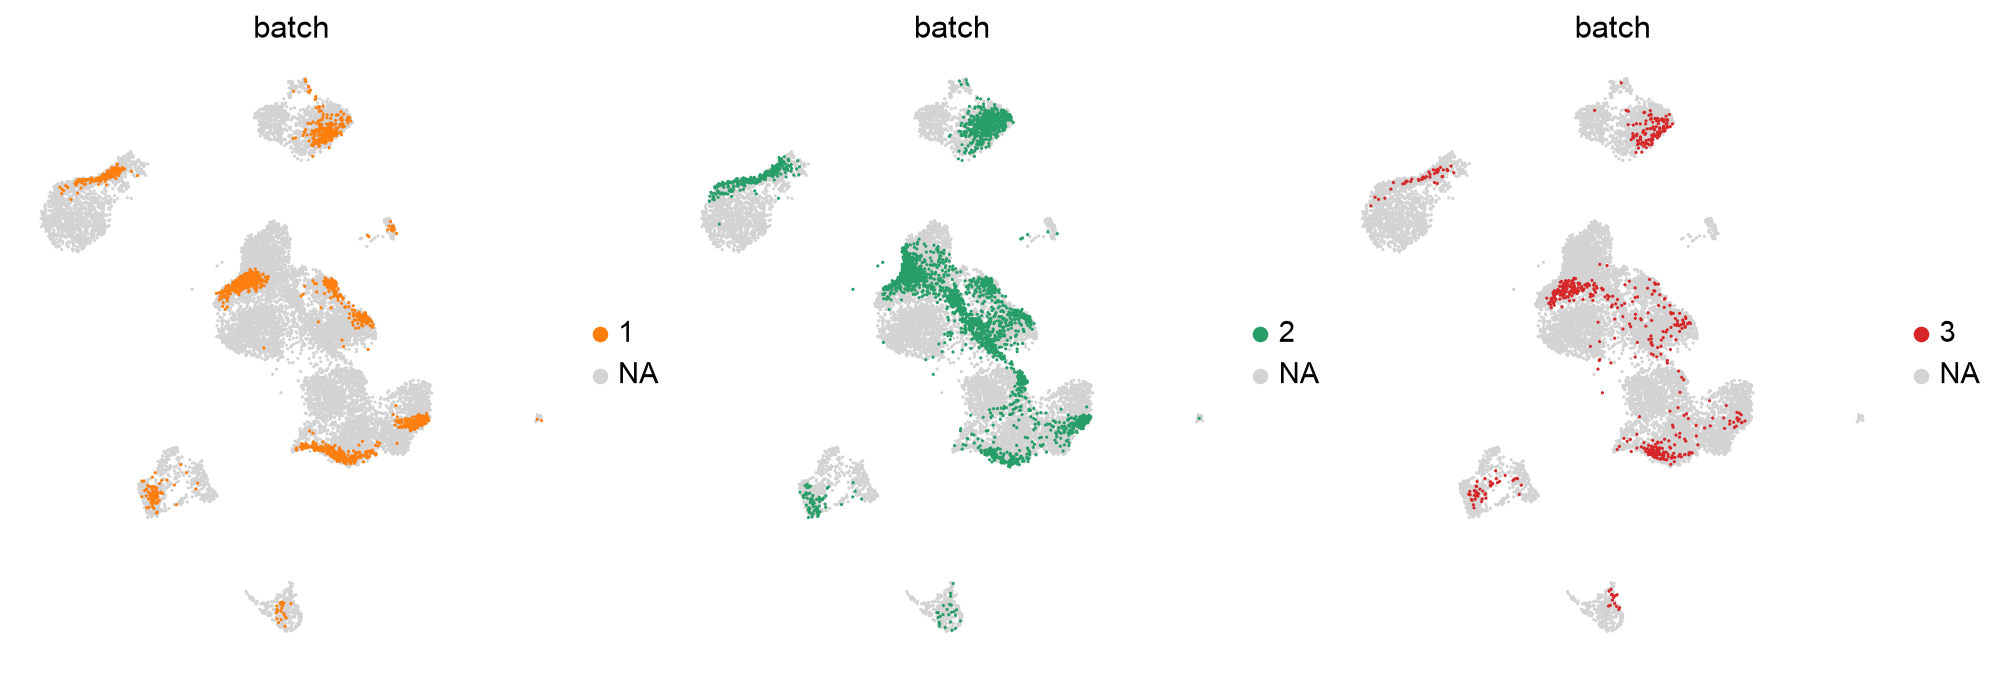

In [ ]:
# highlightig one batch at a time
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for batch, ax in zip(["1", "2", "3"], axes, strict=True):
    sc.pl.umap(adata_concat, color="batch", groups=[batch], ax=ax, show=False)

# shows where each study's cells are concentrated on the UMAP, so we can see how well they are integrated

- BBKNN mixes batches well when all batches share the same cell types
- ingest preserves a clean reference structure and can harmonise or fill in labels but it cannot recognise cell types missing from the reference
- evulate integration quantively using confusion table is essential as disagreement can mean a method error or inconsistent original anotations